<a href="https://colab.research.google.com/github/Amritavarc/MPM_200_Chennapragada/blob/main/notebooks/assignment_1_will__hummers_survive_AmritaChennapragada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [80]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [81]:
beep_colab()     # press ▶ if your browser blocks autoplay

say ("Welcome to Hummingbird HQ, Dr. Pandit!", by = "bat")


 ________________________________________ 
< Welcome to Hummingbird HQ, Dr. Pandit! >
 ---------------------------------------- 
               \
                \

        __.--'\     \.__./     /'--.__
    _.-'       '.__.'    '.__.'       '-._
  .'                                      '.
 /                                          \
|                                            |
|                                            |
 \         .---.              .---.         /
  '._    .'     '.''.    .''.'     '.    _.'
     '-./            \  /           \.-'
                      ''mrf

In [82]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [83]:
#url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200/main/data/Hummingbird_data.csv"
data <- read.csv("/content/sample_data/Hummingbird_data.csv")
colnames(data)


[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

In [84]:
# your code here

dim (data)
nrow(data)
ncol(data)

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [85]:
str(data)
data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:** Colums that are characters are: Admitted, disposition_binary, place, F_Aid, Species_e, Sex_e, Age_e, season, r, Grean_Orange, and ID. The only colum that is a number (integer) is Brought_in_after.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [86]:
set.seed(0128)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [87]:
# your code here
dim (model_data)
nrow(model_data)
ncol(model_data)
str(model_data)

[1] 5000   12

[1] 5000

[1] 12

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "11/19/2015" "6/9/2013" "5/14/2010" "6/14/2014" ...
 $ Disposition_binary: chr  "Died" "Released" "Released" "Released" ...
 $ Place             : chr  "malibu" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "No" "Yes" ...
 $ Species_e         : chr  "ANHU" "Non-selasphorus" "Non-selasphorus" "Non-selasphorus" ...
 $ Sex_e             : chr  "Female-like " "unknown" "unknown" "unknown" ...
 $ Age_e             : chr  "adult-like" "Nestling" "Nestling" "Nestling" ...
 $ Brought_in_after  : int  0 0 0 1 1 0 0 0 1 0 ...
 $ season            : chr  "Fall" "Summer" "Spring" "Summer" ...
 $ r                 : chr  "unknown" "nest-related" "found on the ground" "found on the ground" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "6541_ANHU" "4754_ANHU" "3953_ANHU" "5046_ANHU" ...


**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:** Admitted data is a continuous variable. "ID" is useful to identify which data in each row corresponds to which specific hummingbird.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [88]:
write.csv(model_data, "/content/outputs/Hummingbird_data_AmritaChennapragada.csv", row.names = FALSE)


## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [89]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4163
Santa Barbara,73
malibu,764


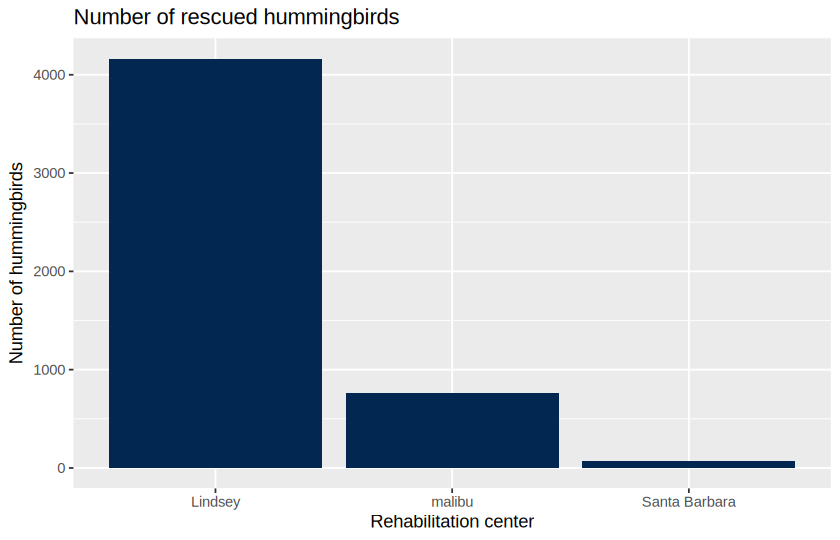

In [90]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [91]:
ggsave("/content/outputs/rehab_counts_AmritaChennapragada.pdf", plot = p, width = 4, height = 3, units = "in")

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:**
"/content/outputs/rehab_counts_AmritaChennapragada.pdf" basically tells R the directory pathway to where i want the graph save. Plot = p tells R that I want to save a plot. Width = 4, height = 3, and units = "in" tell R the dimenssions of the graph.

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:** Raw counts are not enough. We need to look at survivorship tosee what which birds die more where.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [92]:
df1 <- model_data %>%
  group_by(F_Aid, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df1

df2 <- model_data %>%
  group_by(season, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df2

df3 <- model_data %>%
  group_by(r, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df3

F_Aid,Disposition_binary,count
<chr>,<chr>,<int>
No,Died,2084
No,Released,1189
Yes,Died,1128
Yes,Released,599


season,Disposition_binary,count
<chr>,<chr>,<int>
Fall,Died,389
Fall,Released,63
Spring,Died,1305
Spring,Released,938
Summer,Died,961
Summer,Released,606
Winter,Died,557
Winter,Released,181


r,Disposition_binary,count
<chr>,<chr>,<int>
caught by domestic animal,Died,483
caught by domestic animal,Released,184
found inside,Died,114
found inside,Released,41
found on the ground,Died,1430
found on the ground,Released,723
nest-related,Died,256
nest-related,Released,405
suspect torpor-like state,Died,84


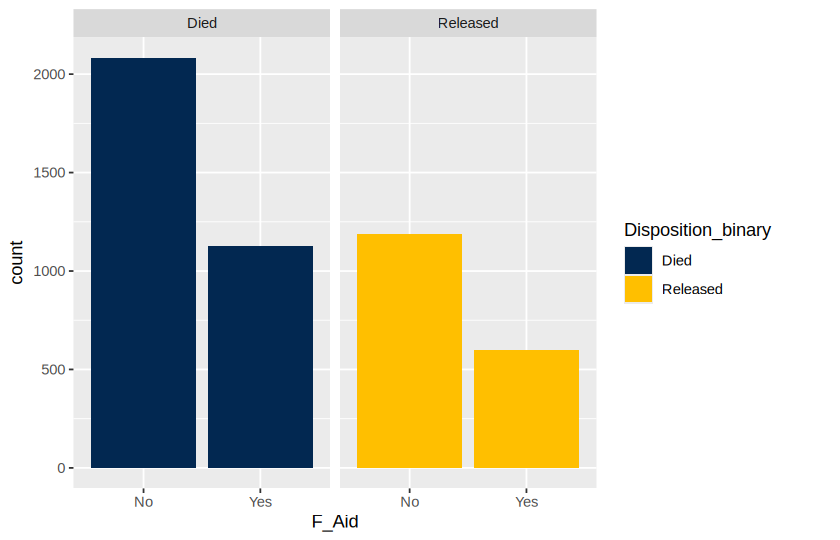

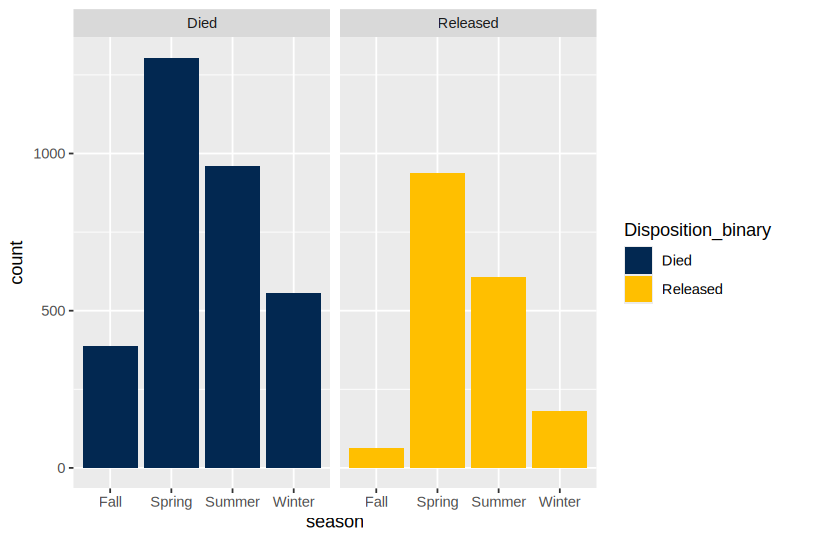

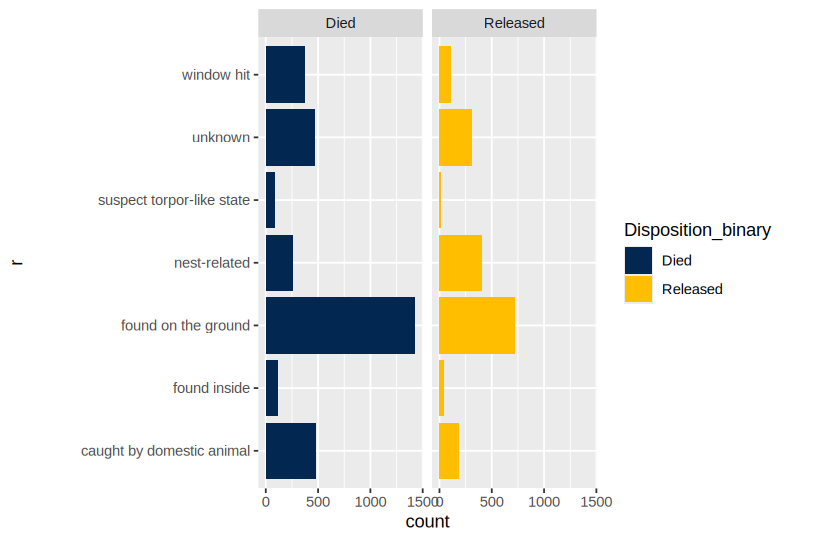

In [93]:
ggplot(df1, aes(y = F_Aid, x = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df2, aes(x = count, y = season, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df3, aes(x = r, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))


**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:** My plots and table look at aid status (whehter aid was given or not), season, and reason for admission are reasons for death or release. For aid status, regardless of whether aid was given or not, both groups have significant deaths compared to release. In season, it appears that their are more deaths and releases in Spring (with there being more deaths). Fall had the least number of deaths and releases. For reason admitted, "found on the ground" has the most number or deaths and releases. We could use probability tests to check whether there is an association.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2692,0.6466491
Lindsey,Released,1471,0.3533509
Santa Barbara,Died,43,0.5890411
Santa Barbara,Released,30,0.4109589
malibu,Died,477,0.6243455
malibu,Released,287,0.3756545


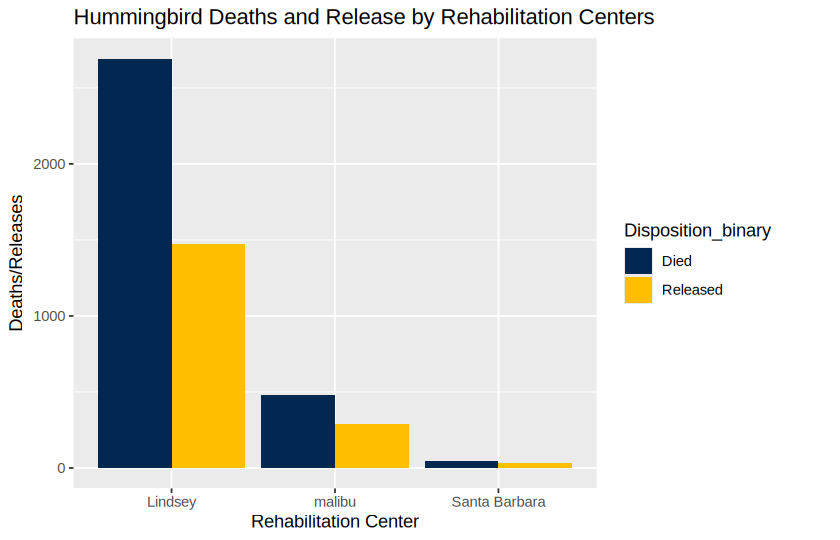

In [94]:
proportions <- model_data %>%
  group_by(Place , Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = count, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation Center") +
  ylab("Deaths/Releases") +
  labs(title = "Hummingbird Deaths and Release by Rehabilitation Centers")+
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  non-Selasphorus                 4159                0
  Selasphorus                        0              841

Species_group,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Selasphorus,Died,536,0.6373365
Selasphorus,Released,305,0.3626635
non-Selasphorus,Died,2676,0.6434239
non-Selasphorus,Released,1483,0.3565761


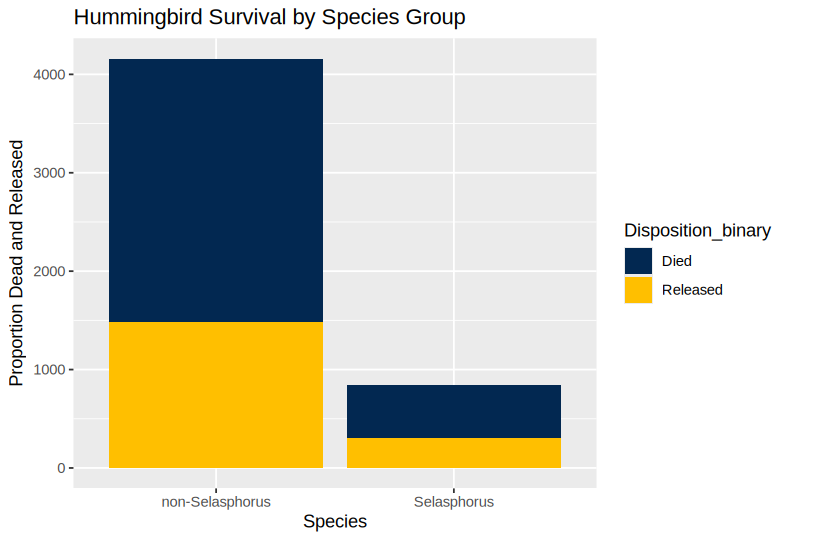

In [95]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus","non-Selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")%>%
  group_by(Species_group)%>%
  mutate(proportion = count/sum(count))

species_distribution


ggplot(species_distribution, aes(x = Species_group, y = count, fill = Disposition_binary)) +
  geom_col() +
  xlab("Species") +
  ylab("Proportion Dead and Released") +
  labs(title = "Hummingbird Survival by Species Group")+
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

✍️ **Your answer:** Between Selaphorus and non-Selaphorus, the proportions look similar.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [96]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

✍️ **Your answer:** format rearranges the data (or in in this case numbers) around for us. If we did "%d/%m/%Y" the date and month numbers would be switched around.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `____` Why?

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

My answer: I think Winter or Spring because of breeding/nesting season. The wind and heavy rain might hurt hummingbirds too.

In [97]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

admissions_by_month

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

admissions_by_year

Admitted_month,Species_group,count
<chr>,<chr>,<int>
1991-01,non-Selasphorus,12
1991-02,non-Selasphorus,2
1991-03,Selasphorus,2
1991-03,non-Selasphorus,15
1991-04,Selasphorus,7
1991-04,non-Selasphorus,17
1991-05,Selasphorus,3
1991-05,non-Selasphorus,13
1991-06,non-Selasphorus,22


Admitted_year,count
<chr>,<int>
1991,133
1992,135
1993,137
1994,127
1995,138
1996,145
1997,137
1998,139
1999,153


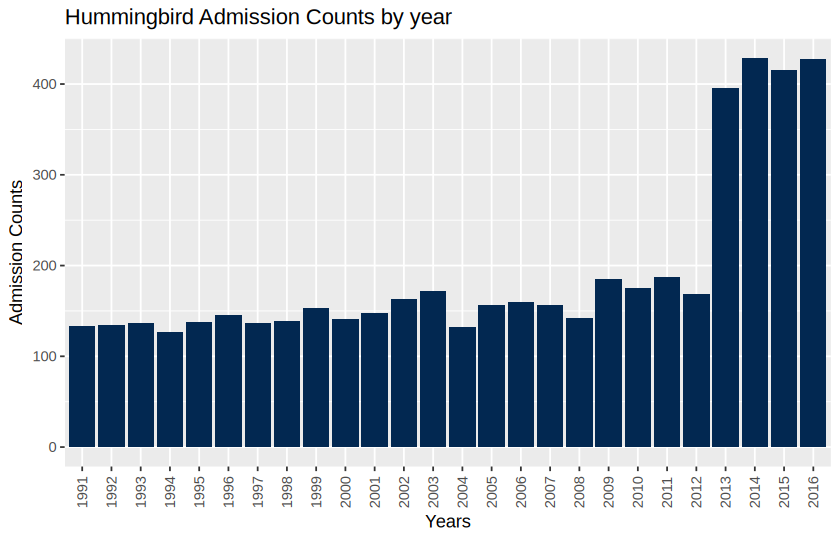

In [98]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Years") +
  ylab("Admission Counts") +
  labs(title = "Hummingbird Admission Counts by year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way

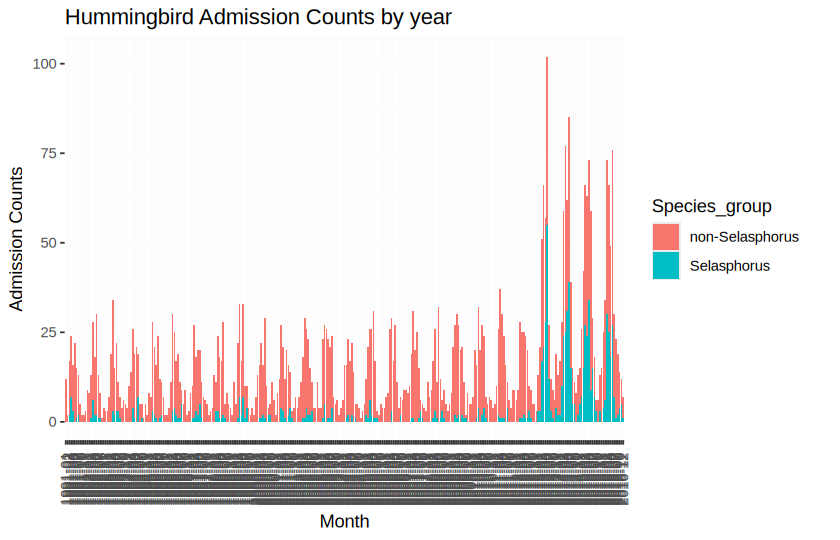

In [99]:
ggplot(admissions_by_month, aes(x = Admitted_month, y = count, fill = Species_group)) +
  geom_col() +
  xlab("Month") +
  ylab("Admission Counts") +
  labs(title = "Hummingbird Admission Counts by year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [100]:
# your investigation here
admissions_by_year_place <- model_data %>%
  count(Admitted_year_date = format(Admitted_date, "%Y"), Place)

admissions_by_year_place


Admitted_year_date,Place,n
<chr>,<chr>,<int>
1991,Lindsey,133
1992,Lindsey,135
1993,Lindsey,137
1994,Lindsey,127
1995,Lindsey,138
1996,Lindsey,145
1997,Lindsey,137
1998,Lindsey,139
1999,Lindsey,153


✍️ **Your answer:** They did not suddenly triple because two new rehab centers openned in malibu and Santa Barabara. This indicates more reporting.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [101]:
# your detective work here

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:**
a. One thing in this data that surprised me is how Spring appeared to have the most number of admissions. Also despite aid being given to some birds, there was still a high mortality rate; it appears that aid did not impact survival or release.

b. One error I had was a syntax error where I forgot to put a '.' before the word group. The error message at the bottom helped me figured out I was missing a period.

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [102]:
beep_colab("smb_stage_clear")   # mission complete 🍄

# Section 4: Running full model and model selection

1. Complete the code and fit a full model

In [104]:
model_data$Disposition_binary <- as.factor(model_data$Disposition_binary)
str(model_data)

'data.frame':	5000 obs. of  14 variables:
 $ Admitted          : chr  "11/19/2015" "6/9/2013" "5/14/2010" "6/14/2014" ...
 $ Disposition_binary: Factor w/ 2 levels "Died","Released": 1 2 2 2 1 1 2 1 1 1 ...
 $ Place             : chr  "malibu" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "No" "Yes" ...
 $ Species_e         : chr  "ANHU" "Non-selasphorus" "Non-selasphorus" "Non-selasphorus" ...
 $ Sex_e             : chr  "Female-like " "unknown" "unknown" "unknown" ...
 $ Age_e             : chr  "adult-like" "Nestling" "Nestling" "Nestling" ...
 $ Brought_in_after  : int  0 0 0 1 1 0 0 0 1 0 ...
 $ season            : chr  "Fall" "Summer" "Spring" "Summer" ...
 $ r                 : chr  "unknown" "nest-related" "found on the ground" "found on the ground" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "6541_ANHU" "4754_ANHU" "3953_ANHU" "5046_ANHU" ..

In [105]:
fullmodel = glm(Disposition_binary ~ r + Green_Orange + season + F_Aid +
  Species_e , data = model_data, family = binomial(link = "logit"))
fullmodel



Call:  glm(formula = Disposition_binary ~ r + Green_Orange + season + 
    F_Aid + Species_e, family = binomial(link = "logit"), data = model_data)

Coefficients:
                 (Intercept)                 rfound inside  
                    -1.90263                       0.09344  
        rfound on the ground                 rnest-related  
                     0.11200                       0.61574  
  rsuspect torpor-like state                      runknown  
                    -0.91014                       0.40298  
                 rwindow hit  Green_OrangeSelasphorus spp.  
                    -0.08270                       0.17687  
                seasonSpring                  seasonSummer  
                     1.06489                       0.97502  
                seasonWinter                      F_AidYes  
                     0.47060                      -0.11079  
               Species_eBCHU      Species_eNon-selasphorus  
                     0.35156               

2. use following command with full model to do stepwise model selection

In [106]:
backward_model = step(fullmodel,k=2,direction = "backward",test="Chisq")
names(backward_model)

Start:  AIC=5947.56
Disposition_binary ~ r + Green_Orange + season + F_Aid + Species_e


Step:  AIC=5947.56
Disposition_binary ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           5919.6 5947.6                      
- F_Aid      1   5922.3 5948.3   2.746   0.09751 .  
- r          6   5972.9 5988.9  53.388 9.803e-10 ***
- season     3   6006.9 6028.9  87.351 < 2.2e-16 ***
- Species_e  3   6114.7 6136.7 195.115 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


[1] "coefficients"      "residuals"         "fitted.values"    
 [4] "effects"           "R"                 "rank"             
 [7] "qr"                "family"            "linear.predictors"
[10] "deviance"          "aic"               "null.deviance"    
[13] "iter"              "weights"           "prior.weights"    
[16] "df.residual"       "df.null"           "y"                
[19] "converged"         "boundary"          "model"            
[22] "call"              "formula"           "terms"            
[25] "data"              "offset"            "control"          
[28] "method"            "contrasts"         "xlevels"          
[31] "anova"

In [107]:
forward_model = step(fullmodel,k=2,direction = ,test="Chisq")

Start:  AIC=5947.56
Disposition_binary ~ r + Green_Orange + season + F_Aid + Species_e


Step:  AIC=5947.56
Disposition_binary ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           5919.6 5947.6                      
- F_Aid      1   5922.3 5948.3   2.746   0.09751 .  
- r          6   5972.9 5988.9  53.388 9.803e-10 ***
- season     3   6006.9 6028.9  87.351 < 2.2e-16 ***
- Species_e  3   6114.7 6136.7 195.115 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


1. There are 31 model properties
2. Non-selasphorus has the highest odds ration
3. Yes, it matters **bold text**

### !!!Answer Questions in the Assignment

# Section 5: explore the glm object

In [108]:
names(backward_model)

[1] "coefficients"      "residuals"         "fitted.values"    
 [4] "effects"           "R"                 "rank"             
 [7] "qr"                "family"            "linear.predictors"
[10] "deviance"          "aic"               "null.deviance"    
[13] "iter"              "weights"           "prior.weights"    
[16] "df.residual"       "df.null"           "y"                
[19] "converged"         "boundary"          "model"            
[22] "call"              "formula"           "terms"            
[25] "data"              "offset"            "control"          
[28] "method"            "contrasts"         "xlevels"          
[31] "anova"

explore individual attributes of the fitted model and read about it in the R documentation

In [109]:
install.packages("sjPlot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [110]:
library(sjPlot)

In [111]:
table_html <- tab_model(backward_model)
IRdisplay::display_html(as.character(table_html))

Disposition_binary 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.15 
 0.11 – 0.20 
 <0.001 
 
 
 r [found inside] 
 1.10 
 0.73 – 1.63 
 0.649 
 
 
 r [found on the ground] 
 1.12 
 0.92 – 1.37 
 0.271 
 
 
 r [nest-related] 
 1.85 
 1.43 – 2.40 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.40 
 0.20 – 0.75 
 0.007 
 
 
 r [unknown] 
 1.50 
 1.19 – 1.89 
 0.001 
 
 
 r [window hit] 
 0.92 
 0.70 – 1.22 
 0.561 
 
 
 season [Spring] 
 2.90 
 2.19 – 3.89 
 <0.001 
 
 
 season [Summer] 
 2.65 
 1.99 – 3.58 
 <0.001 
 
 
 season [Winter] 
 1.60 
 1.17 – 2.22 
 0.004 
 
 
 F Aid [Yes] 
 0.90 
 0.78 – 1.02 
 0.098 
 
 
 Species e [BCHU] 
 1.42 
 0.68 – 2.85 
 0.329 
 
 
 Species e [Non-selasphorus] 
 3.39 
 2.85 – 4.05 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.19 
 1.00 – 1.42 
 0.043 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.119 
 

 
 
 
 

 
 
 
 
   
 Disposition_binary 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.15 
 0.11 – 0.20 
 <0.001 
 
 
 r [found inside] 
 1.10 
 0.73 – 1.63 
 0.649 
 
 
 r [found on the ground] 
 1.12 
 0.92 – 1.37 
 0.271 
 
 
 r [nest-related] 
 1.85 
 1.43 – 2.40 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.40 
 0.20 – 0.75 
 0.007 
 
 
 r [unknown] 
 1.50 
 1.19 – 1.89 
 0.001 
 
 
 r [window hit] 
 0.92 
 0.70 – 1.22 
 0.561 
 
 
 season [Spring] 
 2.90 
 2.19 – 3.89 
 <0.001 
 
 
 season [Summer] 
 2.65 
 1.99 – 3.58 
 <0.001 
 
 
 season [Winter] 
 1.60 
 1.17 – 2.22 
 0.004 
 
 
 F Aid [Yes] 
 0.90 
 0.78 – 1.02 
 0.098 
 
 
 Species e [BCHU] 
 1.42 
 0.68 – 2.85 
 0.329 
 
 
 Species e [Non-selasphorus] 
 3.39 
 2.85 – 4.05 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.19 
 1.00 – 1.42 
 0.043 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.119 
 

 

 
 
   
 Disposition_binary 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.15 
 0.11 – 0.20 
 <0.001 
 
 
 r [found inside] 
 1.10 
 0.73 – 1.63 
 0.649 
 
 
 r [found on the ground] 
 1.12 
 0.92 – 1.37 
 0.271 
 
 
 r [nest-related] 
 1.85 
 1.43 – 2.40 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.40 
 0.20 – 0.75 
 0.007 
 
 
 r [unknown] 
 1.50 
 1.19 – 1.89 
 0.001 
 
 
 r [window hit] 
 0.92 
 0.70 – 1.22 
 0.561 
 
 
 season [Spring] 
 2.90 
 2.19 – 3.89 
 <0.001 
 
 
 season [Summer] 
 2.65 
 1.99 – 3.58 
 <0.001 
 
 
 season [Winter] 
 1.60 
 1.17 – 2.22 
 0.004 
 
 
 F Aid [Yes] 
 0.90 
 0.78 – 1.02 
 0.098 
 
 
 Species e [BCHU] 
 1.42 
 0.68 – 2.85 
 0.329 
 
 
 Species e [Non-selasphorus] 
 3.39 
 2.85 – 4.05 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.19 
 1.00 – 1.42 
 0.043 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.119 
 

 
NULLTRUE